# Week 8 Lab: Statistical Language Models
**COMP1023 Natural Language Technologies, School of Computer Science, TU Dublin**
Dr Muhammad Abeer Irfan

In this lab we build language models by **counting**, then use them to **predict**, **generate** and **measure**.
First we use the NLTK library on a tiny corpus, so you can see every number. Then we open the box and build the same things ourselves, on a much bigger corpus.

| Part | What we do |
|---|---|
| 1 | Introduction: what a language model does |
| 2 | NLTK on a tiny corpus: n-grams, counts, probabilities, generation, perplexity |
| 3 | Load a bigger corpus (BBC news from Week 6, or a free fallback) |
| 4 | Zipf's law: a few words do most of the work |
| 5 | Shannon's experiment: more context, more English-looking text |
| 6 | Word bigrams from scratch |
| 7 | Generate text by predicting on repeat |
| 8 | Sparsity: how many n-grams have we never seen? |
| 9 | Perplexity on held-out text: which model is least surprised? |
| 10 | Your turn |

Run each cell with **Shift + Enter**, from top to bottom. NLTK documentation: https://www.nltk.org/api/nltk.lm.html

## Part 1: Introduction to language modelling

A language model learns the patterns of a language so that, given *n* tokens, it can predict token *n + 1*.

* Given the single word "Merry", the next word is very likely "Christmas". One word of context is enough here.
* Given "turned the", there are many reasonable next words and none dominates. With more context, "she jumped into the car and turned the", a model should expect "key" or "keys", and maybe "wheel", "engine" or "ignition".

Clues can be much further back. "He sat with the ring in his pocket, perspiring, anxious, waiting for the perfect moment that would never come. Finally he slid his hand from his pocket, and asked Marie if she would..." Here "marry" fits, but a model that looks back only two, three or even four words would not predict it.

Until recently, language models were built statistically with **n-grams**: an algorithm reads a large body of text, builds tables of all 1-grams, 2-grams, 3-grams (and maybe 4- and 5-grams), and uses simple probability calculations to score words given a context. NLTK (the Natural Language Toolkit) has a simple implementation that we use first.

In [1]:
import re, math, random, collections
import matplotlib.pyplot as plt

import nltk
from nltk.util import ngrams as nltk_ngrams
from nltk.lm import MLE
from nltk.lm.preprocessing import padded_everygram_pipeline
from nltk import word_tokenize

# The tokenizer needs a small model file. Newer NLTK versions call it 'punkt_tab'.
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

def safe_word_tokenize(s):
    try:
        return word_tokenize(s)
    except LookupError:                       # no internet: fall back to a simple tokenizer
        return re.findall(r"\w+(?:[-']\w+)*|[^\w\s]", s)

print("NLTK version:", nltk.__version__)

Matplotlib is building the font cache; this may take a moment.


NLTK version: 3.10.0


## Part 2: NLTK on a tiny corpus

### 2.1 The corpus
Language modelling is all about processing text. Here are some short texts written out in full so you can look at them: the titles and plot summaries of *The Lord of the Rings*. Normally we would load sentences from a file or a corpus.

In [2]:
lotr_docs = ["The Lord of the Rings",
        "The Fellowship of the Ring",
        "The Two Towers",
        "The return of the King",
       "In the Second Age of Middle-earth, the lords of Elves, Dwarves, and Men are given Rings of Power. Unbeknownst to them, the Dark Lord Sauron forges the One Ring in Mount Doom, installing into it a great part of his power to dominate the other Rings, so he might conquer Middle-earth. A final alliance of men and elves battles Sauron's forces in Mordor, where Prince Isildur of Gondor severs Sauron's finger, and the Ring with it, thereby destroying his physical form. With Sauron's first defeat, the Third Age of Middle-earth begins. Unfortunately, the Ring's influence corrupts Isildur, who takes it for himself. Isildur is later killed by Orcs, and the Ring is lost for 2,500 years, until it is found by Gollum, who owns it for five centuries. The Ring is then found by a hobbit named Bilbo Baggins, who turns invisible when he puts it on, but is unaware of its history.",
        "Sixty years later, Bilbo celebrates his 111th birthday in the Shire, reuniting with his old friend, Gandalf the Grey. Bilbo reveals that he intends to leave the Shire for one last adventure, and he leaves his inheritance, including the Ring, to his nephew, Frodo. Although Bilbo has begun to become corrupted by the Ring and tries to keep it for himself, Gandalf intervenes. Gandalf, suspicious of the Ring, tells Frodo to keep it secret and to keep it safe. Gandalf then investigates the Ring, discovers its true nature, and returns to warn Frodo. Gandalf also learns that Gollum was captured and tortured by Orcs, and that Gollum uttered two words during his interrogation: Shire and Baggins. Gandalf instructs Frodo to leave the Shire, accompanied by his friend Samwise Gamgee. Gandalf rides to Isengard to meet with fellow wizard Saruman the White, but learns that he has joined forces with Sauron, who has dispatched his nine undead Nazgûl servants to find Frodo. After a brief battle, Saruman imprisons Gandalf.",
       "Frodo and Sam are joined by fellow hobbits Merry and Pippin, and they evade the Nazgûl, arriving in Bree, where they are meant to meet Gandalf. However, Gandalf never arrives, and they are instead aided by a ranger named Strider, a friend of Gandalf's, who promises to escort them to Rivendell. The hobbits are ambushed by the Nazgûl on Weathertop, and their leader, the Witch-King, stabs Frodo with a cursed Morgul blade. Arwen, an elf and Strider's betrothed, locates Aragorn and the Hobbits and aids Frodo, rescuing him and incapacitating the Nazgûl. She takes him to Rivendell, where he is healed. Frodo meets Gandalf, who escaped Isengard with help from Gwaihir, a giant eagle. That night, Aragorn reunites with Arwen in Rivendell, where they confirm their love and commitment for each other. Arwen's father, Lord Elrond, holds a council that decides the Ring must be destroyed in Mount Doom. While the members argue, Frodo volunteers to take the Ring, accompanied by Gandalf, Sam, Merry, Pippin, elf Legolas, dwarf Gimli, Boromir of Gondor, and Strider, who is revealed to be Aragorn, Isildur's heir and the rightful King of Gondor. Bilbo gives Frodo his sword, Sting. The Fellowship of the Ring sets off, but Saruman's magic forces them to travel through the Mines of Moria, much to Gandalf's displeasure.",
       "The Fellowship discovers that the dwarves within Moria have been slain, and they are attacked by Orcs and a cave troll. They defeat them, but are confronted by Durin's Bane, a Balrog residing within the mines. Gandalf casts the Balrog into a vast chasm, but it drags Gandalf down into the darkness with it. The rest of the Fellowship, now led by Aragorn, reaches Lothlórien, home to elves Galadriel and Celeborn. Galadriel privately informs Frodo that only he can complete the quest, and that one of his friends will try to take the Ring. Meanwhile, Saruman creates an army of Uruk-hai to track down and kill the Fellowship.",
       "The Fellowship leaves Lothlórien by river to Parth Galen. Frodo wanders off and is confronted by Boromir, who tries to take the Ring in desperation. Afraid of the Ring corrupting his friends, Frodo decides to travel to Mordor alone. The Fellowship is then ambushed by the Uruk-hai. Merry and Pippin are taken captive, and Boromir is mortally wounded by the Uruk chieftain, Lurtz. Aragorn arrives and slays Lurtz, and watches Boromir die peacefully. Sam follows Frodo, accompanying him to keep his promise to Gandalf to protect Frodo, while Aragorn, Legolas, and Gimli go to rescue Merry and Pippin.",
       "Awakening from a dream of Gandalf the Grey battling the Balrog, Frodo Baggins and his friend Samwise Gamgee find themselves lost in the Emyn Muil near Mordor and soon become aware that they are being stalked by Gollum, the former owner of the One Ring. After capturing him, a sympathetic Frodo decides to use Gollum as a guide to Mordor, despite Sam's objections.",
       "Meanwhile, Aragorn, Legolas and Gimli pursue the Uruk-hai to save their companions Merry and Pippin. The Uruk-hai are ambushed by a group of Rohirrim, while the two Hobbits escape into Fangorn Forest and encounter Treebeard, an Ent. Aragorn's group later meets the Rohirrim and their leader Éomer, who reveals that they have been exiled by their king Théoden who is being manipulated by Saruman and his servant Gríma Wormtongue into turning a blind eye to Saruman's forces running rampant in Rohan. While searching for the Hobbits in Fangorn, Aragorn's group encounters Gandalf, who, after succumbing to his injuries while killing the Balrog in Moria, has been resurrected as Gandalf the White to help save Middle-earth.",
       "Aragorn's group travels to Rohan's capital city Edoras, where Gandalf releases Théoden from Saruman's influence and Wormtongue is banished. After learning of Saruman's plans to wipe out Rohan with his Uruk-hai army, Théoden decides to evacuate his citizens to Helm's Deep, an ancient fortress that has provided refuge to Rohan's people in times past, while Gandalf departs to acquire the aid of Éomer's army. Aragorn establishes a friendship with Théoden's niece, Éowyn, who quickly becomes infatuated with him. That night, Aragorn experiences a dream of him meeting with Arwen who then tells him that he must depart with Frodo and reassures him when he doesn't feel confident enough that his path is set for him. When the refugees come under attack by Warg-riding Orcs sent by Saruman, Aragorn falls off a cliff and is presumed dead. However, he is awoken by his horse Brego and rides to Helm's Deep. That same night, Arwen is told by her father Elrond that Aragorn will not be returning. He tells her that if she remains in Middle-Earth, only death and destruction await her, even if Aragorn were to survive and become King of Gondor, and if Sauron is defeated again, she will die alone. This convinces her to reluctantly depart for Valinor. The defenders at Helm's Deep are joined by a detachment of Elves from Lothlórien. The Uruk-hai army arrives at Helm's Deep that night and a night-long battle ensues. The Uruk-hai breach the outer wall using gunpowder-like explosives and force the remaining defenders to retreat into the inner castle.",
       "Merry and Pippin, having convinced Treebeard that they were allies, are brought to an Ent Council in Fangorn where the Ents decide not to assist in the war. Pippin then tells Treebeard to take them in the direction of Isengard, where they witness the devastation caused to the forest by Saruman's war efforts. An enraged Treebeard summons the Ents and they storm Isengard, drowning the orcs by breaking their river dam and stranding Saruman in Orthanc.",
       "At Helm's Deep, Aragorn convinces a despairing Théoden to ride out and meet the Uruks in one last charge. Gandalf and Éomer's horsemen arrive at sunrise, turning the tide of the battle. The Uruk-hai flee into Fangorn forest, which has moved closer to the battle at the urging of Treebeard, where they are destroyed. Gandalf warns that Sauron's retaliation will be terrible and swift.",
       "Meanwhile, Gollum leads Frodo and Sam through the Dead Marshes to the Black Gate but convinces them to enter Mordor by an alternative route. Frodo and Sam are captured by the Rangers of Ithilien led by Faramir, brother of the late Boromir. Frodo helps Faramir catch Gollum to save him from being killed and Faramir learns of the One Ring and takes his captives with him to Gondor to win his father's respect. While passing through the besieged Gondorian city of Osgiliath, Sam reveals that Boromir was driven mad by the Ring and tried to take it. An attacking Nazgûl nearly captures Frodo, who momentarily attacks Sam before coming to his senses, forcing Sam to remind him that they are fighting for the good still left in Middle-earth. Faramir is impressed by Frodo and releases them along with Gollum. While leading the hobbits once more, Gollum decides to take revenge on Frodo and reclaim the Ring by leading the group to Her upon arriving at Cirith Ungol.",
       "Two Hobbits, Sméagol and Déagol, are fishing when Déagol discovers the One Ring in the river. Sméagol is ensnared by the Ring, and kills his friend for it. He retreats into the Misty Mountains as the Ring twists his body and mind, until he becomes the creature Gollum.",
       "Centuries later, during the War of the Ring, Gandalf leads Aragorn, Legolas, Gimli, and King Théoden to Isengard, where they reunite with Merry and Pippin. Gandalf retrieves the defeated Saruman's palantír. Pippin later looks into the seeing-stone and is telepathically attacked by Sauron. From Pippin's description of his visions, Gandalf surmises that Sauron will attack Gondor's capital Minas Tirith. He rides there to warn Gondor's steward Denethor, taking Pippin with him.",
       "Gollum leads Frodo Baggins and Samwise Gamgee to Minas Morgul, where they watch the Witch-king, leader of the nine Nazgûl, lead an army of Orcs towards Gondor. The hobbits begin climbing a stair carved in the cliff face that will take them into Mordor via a secret way, unaware that Gollum plans to kill them and take the Ring. The Witch-king and his forces strike and overwhelm Osgiliath, forcing Faramir and his garrison to retreat to Minas Tirith.",
       "Gollum disposes of the Hobbits' food, blaming Sam. Believing that Sam desires the Ring, Frodo tells him to go home before he and Gollum continue to the tunnel leading to Mordor. Gollum tricks him into venturing into the lair of the giant spider Shelob. Frodo narrowly escapes and confronts Gollum, telling him that he must destroy the Ring for both their sakes. Gollum attacks Frodo but falls down a chasm. Frodo continues on, but Shelob discovers, paralyses, and binds him. However, Sam returns and injures Shelob, driving her away. Sam hides as Orcs appear and take Frodo with them. The Orcs start a fight because of ownership of Frodo's mithril vest, allowing Sam to escape with Frodo and continue their journey.",
       "Aragorn learns from Elrond that Arwen's strength is fading, having refused to leave and wishing to stay in Middle Earth, reunite with Aragorn, start a family, and willingly become mortal, after seeing a vision of her son with Aragorn. Arwen convinces a reluctant Elrond to accept her choice of staying in Middle Earth and to arm Aragorn with Andúril, a sword recreated by Rivendell blacksmiths on Elrond's orders from the shards of Isildur's sword, Narsil, so he can reclaim his birthright while gaining reinforcements from the Dead Men of Dunharrow. Joined by Legolas and Gimli, Aragorn travels to the Paths of the Dead, recruiting the Army of the Dead by pledging to release them from the curse Isildur put on them.",
       "Faramir is gravely wounded after a futile effort to retake Osgiliath; believing his son to be dead, Denethor falls into madness. Gandalf is left to defend the city against the Orc army, led by Gothmog. As Gothmog's army forces its way into the city, Denethor attempts to kill himself and Faramir on a pyre. Pippin alerts Gandalf and they save Faramir, but a burning Denethor leaps to his death from the top of Minas Tirith just before Théoden and his nephew, Éomer, arrive with the Rohirrim. During the ensuing battle, they are overwhelmed by the Oliphaunt-riding Haradrim, while the Witch-King mortally wounds Théoden. Though Théoden's niece Éowyn destroys the Witch-king with Merry's help, Théoden succumbs to his wounds. Aragorn arrives with the Army of the Dead, who overcome Sauron's forces and win the battle; Aragorn then frees them from the curse.",
       "Aragorn decides to march upon the Black Gate as a distraction so Frodo and Sam can reach Mount Doom. Aragorn's army draws out Sauron's remaining forces and empties Mordor, allowing Frodo and Sam to reach the volcano, but Gollum attacks them just as they reach Mount Doom. As he stands on the ledge over the volcanic fire, Frodo succumbs to the Ring and claims it as his own, putting it on his finger. Despite Frodo being invisible, Gollum manages to find and attack him, biting his finger off to reclaim the Ring. Frodo fights back, and as they struggle over the Ring, both fall off the ledge. Gollum falls into the lava with the Ring and dies. Frodo clings to the side of the ledge, and Sam rescues him as the Ring disintegrates in the lava. As Frodo and Sam escape, Sauron is destroyed along with his forces and the Nine as Mordor crumbles.",
       "Gandalf flies in with eagles to rescue the Hobbits, who awaken in Minas Tirith and are reunited with the surviving Fellowship. Aragorn is crowned King of Gondor and takes Arwen as his queen. The Hobbits return home to the Shire, where Sam marries Rosie Cotton. A few years later, Frodo departs Middle-earth for the Undying Lands with his uncle Bilbo, Gandalf, and the Elves. He leaves Sam the Red Book of Westmarch, which details their adventures. Sam returns to the Shire, where he embraces Rosie and their children."]

### 2.2 Split each text into words
To make the text easier to process, we split each document into a list of words (tokens). Here is the first one.

In [4]:
lotr_texts = [safe_word_tokenize(s) for s in lotr_docs]
print(lotr_texts[0])
print(len(lotr_texts), "documents,", sum(len(t) for t in lotr_texts), "tokens")

['The', 'Lord', 'of', 'the', 'Rings']
23 documents, 2682 tokens


### 2.3 N-grams
Traditional language modelling is about counting: how often each word occurs, and how often short **sequences** of words occur. A sequence of *n* words is an **n-gram**: 1-grams are single words, 2-grams (bigrams) are pairs, 3-grams (trigrams) are triples. NLTK can list them for us. Here are the 1-, 2- and 3-grams of the first title:

In [5]:
print(list(nltk_ngrams(lotr_texts[0], n=1)))
print(list(nltk_ngrams(lotr_texts[0], n=2)))
print(list(nltk_ngrams(lotr_texts[0], n=3)))

[('The',), ('Lord',), ('of',), ('the',), ('Rings',)]
[('The', 'Lord'), ('Lord', 'of'), ('of', 'the'), ('the', 'Rings')]
[('The', 'Lord', 'of'), ('Lord', 'of', 'the'), ('of', 'the', 'Rings')]


### 2.4 Padding and training
Words at the start and end of a sentence should also appear in full n-grams, so we **pad** each text with start `<s>` and end `</s>` symbols. `padded_everygram_pipeline` does the padding and produces all 1-, 2- and 3-grams (`train`) plus the list of words (`vocab`).

Then `MLE(3)` creates a trigram model using **Maximum Likelihood Estimation** (count and divide), and `fit` does the counting.

In [6]:
lotr_train, lotr_vocab = padded_everygram_pipeline(3, lotr_texts)
lotr_model = MLE(3)
lotr_model.fit(lotr_train, lotr_vocab)
print("Vocabulary size:", len(lotr_model.vocab))

Vocabulary size: 777


### 2.5 Counts and probabilities
At its core, the model is a tool for collecting counts and probabilities.

How many times do "the", "are" and "Balrog" appear? (Capital letters matter: NLTK keeps "The" and "the" separate.)

In [7]:
for w in ["the", "are", "Balrog"]:
    print(f"{w:7s} count = {lotr_model.counts[w]:4d}   P(w) = {lotr_model.score(w):.4f}")

the     count =  145   P(w) = 0.0523
are     count =   18   P(w) = 0.0065
Balrog  count =    4   P(w) = 0.0014


`score(w)` is the count of `w` divided by the total number of tokens: its unigram probability.

How often is "they" followed by "are", and what is P(are | they)? This is the bigram formula:
$P(\text{are} \mid \text{they}) = \dfrac{count(\text{they are})}{count(\text{they})}$

In [8]:
print("count(they are) =", lotr_model.counts[["they"]]["are"])
print("count(they)     =", lotr_model.counts["they"])
print(f"P(are | they)   = {lotr_model.score('are', ['they']):.4f}")

count(they are) = 7
count(they)     = 18
P(are | they)   = 0.3889


### 2.6 Generating text
A language model can also **generate** text: pick a likely next word, add it, repeat. Using the same `random_seed` gives the same sentence every time.

In [9]:
word_list = lotr_model.generate(15, random_seed=2)
print(" ".join(word_list))

vast chasm , but it drags Gandalf down into the lair of the One Ring


**Try:** change `random_seed`. Then go back to 2.4, train with `MLE(2)` and `MLE(1)` instead of `MLE(3)`, and generate again. The text becomes less fluent. Why?

### 2.7 Measuring a model: perplexity
Precision and recall do not suit language models. Instead we use **perplexity**: how surprised the model is by a test text. For a test text $W = w_1 \dots w_N$:

$$PP(W) = P(w_1, \dots, w_N)^{-1/N} = \sqrt[N]{\dfrac{1}{P(w_1, \dots, w_N)}}$$

A higher probability for the test text gives a **lower** perplexity, so **lower is better**. The $N$-th root makes short and long texts comparable.

Perplexity is linked to **cross-entropy**, the loss used to train neural models. The cross-entropy of the text, in bits, is

$$H(W) = -\frac{1}{N} \log_2 P(W)$$

and perplexity is simply $PP(W) = 2^{H(W)}$. (With natural logs, $H = -\frac{1}{N}\ln P(W)$ and $PP = e^{H}$; the answer is the same.)

Below, each test is a list of bigrams, so the model scores P(second word | first word).

In [10]:
tests = {
    "of the, a dream": [("of", "the"), ("a", "dream")],
    "of the":          [("of", "the")],
    "a dream":         [("a", "dream")],
    "the of":          [("the", "of")],
}
for name, test_pairs in tests.items():
    print(f"{name:18s} perplexity = {lotr_model.perplexity(test_pairs):.3f}")

of the, a dream    perplexity = 7.015
of the             perplexity = 2.895
a dream            perplexity = 17.000
the of             perplexity = inf


Notice `inf` for "the of": that pair never appears in the corpus, so its probability is 0 and the perplexity is infinite. An unseen n-gram breaks a plain MLE model. We will measure how common this problem is in Part 8, and fix it with smoothing and interpolation in Part 9.

Now let us open the box. From here on we build the same things ourselves, with plain Python, on a much bigger corpus.

## Part 3: Load a bigger corpus
**Option A (recommended):** set `USE_BBC = True` and upload `bbc_text_cls.csv` from the Week 6 folder when asked (Colab only).
**Option B:** leave `USE_BBC = False` and we download Jane Austen's *Emma* from NLTK's Gutenberg collection. If there is no internet, the cell falls back to the small *Lord of the Rings* corpus from Part 2.

Note: from here on we use our own simple tokenizer that also **lowercases** everything.

In [11]:
USE_BBC = False   # set to True to upload the Week 6 BBC file

if USE_BBC:
    import pandas as pd
    from google.colab import files
    up = files.upload()                       # choose bbc_text_cls.csv
    df = pd.read_csv(next(iter(up)))
    raw_docs = df["text"].tolist()
else:
    try:
        nltk.download("gutenberg", quiet=True)
        from nltk.corpus import gutenberg
        text = gutenberg.raw("austen-emma.txt")
        raw_docs = [p for p in text.split("\n\n") if len(p.split()) > 5]   # paragraphs as documents
    except LookupError:
        print("Could not download Emma, using the Lord of the Rings corpus from Part 2 instead.")
        raw_docs = lotr_docs

def tokenize(s):
    return re.findall(r"[a-z']+", s.lower())

docs = [tokenize(d) for d in raw_docs]
words = [w for d in docs for w in d]
print(f"{len(docs):,} documents | {len(words):,} tokens | {len(set(words)):,} distinct words")

2,250 documents | 160,748 tokens | 7,199 distinct words


## Part 4: Zipf's law
Count every word and plot the most common ones. Notice how quickly the bars fall.

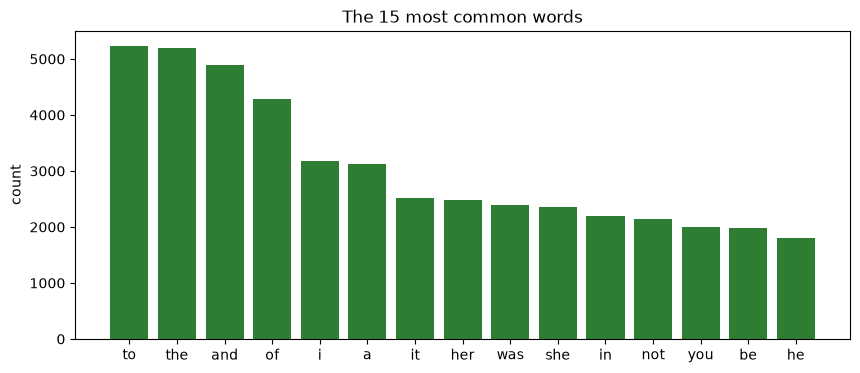

'the' is 3.2% of all tokens
Words seen only once: 2,813


In [12]:
counts = collections.Counter(words)
top = counts.most_common(15)
plt.figure(figsize=(10, 4))
plt.bar([w for w, _ in top], [c for _, c in top], color="#2E7D32")
plt.title("The 15 most common words")
plt.ylabel("count")
plt.show()
print(f"'the' is {counts['the'] / len(words):.1%} of all tokens")
print(f"Words seen only once: {sum(1 for c in counts.values() if c == 1):,}")

## Part 5: Shannon's experiment (1948)
Shannon generated text letter by letter. With **order 0** every letter is equally likely. With higher orders, each letter depends on the letters before it.
**Try:** change `order` from 0 to 5 and compare.

In [ ]:
letters = re.sub(r"[^a-z ]", "", " ".join(words))

def letter_model(order):
    table = collections.defaultdict(collections.Counter)
    for i in range(len(letters) - order):
        table[letters[i:i + order]][letters[i + order]] += 1
    return table

def shannon_text(order, length=120, seed=1):
    random.seed(seed)
    if order == 0:
        return "".join(random.choice("abcdefghijklmnopqrstuvwxyz ") for _ in range(length))
    table = letter_model(order)
    out = letters[:order]
    while len(out) < length:
        nxt = table.get(out[-order:])
        if not nxt:
            break
        out += random.choices(list(nxt), weights=nxt.values())[0]
    return out

for order in [0, 1, 2, 3, 5]:
    print(f"order {order}: {shannon_text(order)}\n")

## Part 6: Word bigrams from scratch
This is what `lotr_model.score('are', ['they'])` did in Part 2, written out ourselves:

$P(w_n \mid w_{n-1}) = \dfrac{count(w_{n-1}, w_n)}{count(w_{n-1})}$

In [ ]:
def ngrams(seq, n):
    return list(zip(*[seq[i:] for i in range(n)]))

print(ngrams("the cat sat on the mat".split(), 2))

bigrams = collections.Counter(b for d in docs for b in ngrams(d, 2))

def p_next(prev, nxt):
    return bigrams[(prev, nxt)] / counts[prev]

print(f"P(the | of) = {p_next('of', 'the'):.3f}")
after_of = collections.Counter({w2: c for (w1, w2), c in bigrams.items() if w1 == "of"})
print("Most likely words after 'of':", [(w, round(c / counts['of'], 3)) for w, c in after_of.most_common(5)])

## Part 7: Generate text, prediction on repeat
This is what `lotr_model.generate` did in Part 2. Pick a likely next word, append it, repeat. Change `seed` and `n` and compare. Why is `n = 1` so much worse?

In [ ]:
def build(n):
    table = collections.defaultdict(collections.Counter)
    for d in docs:
        d = ["<s>"] * (n - 1) + d + ["</s>"]
        for i in range(n - 1, len(d)):
            table[tuple(d[i - n + 1:i])][d[i]] += 1
    return table

def generate(n, length=20, seed=2):
    random.seed(seed)
    table = build(n)
    context = ["<s>"] * (n - 1)
    out = []
    for _ in range(length):
        options = table[tuple(context[-(n - 1):]) if n > 1 else ()]
        w = random.choices(list(options), weights=options.values())[0]
        if w == "</s>":
            break
        out.append(w)
        context.append(w)
    return " ".join(out)

for n in [1, 2, 3]:
    print(f"n={n}: {generate(n)}\n")

## Part 8: Sparsity, the curse of unseen n-grams
Remember the `inf` perplexity in Part 2? Hold out 10% of documents as a test set. What fraction of the test n-grams never appeared in training?

In [ ]:
random.seed(0)
shuffled = docs[:]
random.shuffle(shuffled)
cut = int(0.9 * len(shuffled))
train_docs, test_docs = shuffled[:cut], shuffled[cut:]

V = len(set(words))
print(f"Possible bigrams: {V:,} x {V:,} = {V * V:,}")
for n in [1, 2, 3]:
    seen = set(g for d in train_docs for g in ngrams(d, n))
    test = [g for d in test_docs for g in ngrams(d, n)]
    unseen = sum(g not in seen for g in test) / len(test)
    print(f"{n}-grams in the test set never seen in training: {unseen:.1%}")

## Part 9: Perplexity on held-out text
$PP(W) = P(w_1 \dots w_N)^{-1/N}$, lower is better. To avoid the `inf` problem we **smooth** the unigram (add-one) and **interpolate**: mix trigram, bigram and unigram estimates, so an unseen n-gram never gets zero. We add up log probabilities instead of multiplying, so the number does not become too small for the computer.

In [ ]:
def wrap(d): return ["<s>"] + d + ["</s>"]
u, b, t = collections.Counter(), collections.Counter(), collections.Counter()
for d in map(wrap, train_docs):
    u.update(d); b.update(ngrams(d, 2)); t.update(ngrams(d, 3))
N, Vs = sum(u.values()), len(u) + 1

def p_uni(w):        return (u[w] + 1) / (N + Vs)            # add-one smoothing
def p_bi(p, w):      return b[(p, w)] / u[p] if u[p] else 0
def p_tri(a, p, w):  return t[(a, p, w)] / b[(a, p)] if b[(a, p)] else 0

models = {
    "uniform (all words equal)": lambda d, i: 1 / Vs,
    "unigram":                   lambda d, i: p_uni(d[i]),
    "bigram":                    lambda d, i: 0.7 * p_bi(d[i-1], d[i]) + 0.3 * p_uni(d[i]),
    "trigram":                   lambda d, i: (0.5 * p_tri(d[i-2], d[i-1], d[i]) + 0.3 * p_bi(d[i-1], d[i]) + 0.2 * p_uni(d[i])) if i > 1
                                               else 0.7 * p_bi(d[i-1], d[i]) + 0.3 * p_uni(d[i]),
}

def perplexity(f):
    log_p, n = 0.0, 0
    for d in map(wrap, test_docs):
        for i in range(1, len(d)):
            log_p += math.log(f(d, i)); n += 1
    return math.exp(-log_p / n)

results = {name: perplexity(f) for name, f in models.items()}
for name, pp in results.items():
    print(f"{name:28s} perplexity = {pp:,.0f}")

plt.figure(figsize=(8, 3.5))
plt.barh(list(results)[::-1], list(results.values())[::-1], color="#C62828")
plt.xscale("log"); plt.xlabel("perplexity (log scale, lower is better)")
plt.show()

## Part 10: Your turn
1. In Part 2.6, try different random seeds. Then retrain with `MLE(2)` and `MLE(1)`. Why is the text less fluent?
2. In Part 2.7, add your own test pairs. Which ones give `inf`, and why?
3. In Part 5, at what order does the letter text start to contain real words?
4. In Part 7, generate with `n = 4`. Is the text better, or is it copying the training data? Search the corpus for a phrase to check.
5. In Part 9, change the mixing weights (0.5 / 0.3 / 0.2). Can you get a lower perplexity?
6. Challenge: replace the bigram in Part 9 with add-one smoothing, `(count + 1) / (count(prev) + V)`. What happens to perplexity, and why?
7. On the small *Emma* corpus the trigram can score worse than the bigram, but on the BBC corpus it scores better. Why might corpus size matter?